In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
url="https://raw.githubusercontent.com/nguyen-toan/ISLR/master/dataset/Advertising.csv"
df=pd.read_csv(url)
df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


## Problem Statement: Advertising Sales Prediction Using Linear Regression

The objective of this project is to develop a machine learning model that predicts product sales based on advertising expenditure across different marketing channels. Using the Advertising dataset, the project applies Scikit-learn's Linear Regression algorithm to investigate the relationship between advertising budgets and sales.

Two models are developed and compared: a **simple linear regression model**, which uses TV advertising expenditure as the sole input feature, and a **multiple linear regression model**, which uses TV, radio, and newspaper advertising expenditures as input features.

The models are evaluated using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the coefficient of determination (\(R^2\)) to compare their predictive fit and understand how incorporating multiple advertising channels affects model performance.

The project aims to demonstrate the application of linear regression to a real-world dataset, interpret the learned model parameters, and examine the relationship between advertising expenditure and sales.

In [2]:
print(f"cloumns:\n{df.columns}")
print(f"\ndatatypes:{df.dtypes}")
print(f"\n Missing values:\n{df.isnull().sum()}")

cloumns:
Index(['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')

datatypes:Unnamed: 0      int64
TV            float64
Radio         float64
Newspaper     float64
Sales         float64
dtype: object

 Missing values:
Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64


First five imputs:
[[230.1]
 [ 44.5]
 [ 17.2]
 [151.5]
 [180.8]]

First five targets:
[22.1 10.4  9.3 18.5 12.9]

Shape of x_train:(200, 1)

Shape of y_train:(200,)


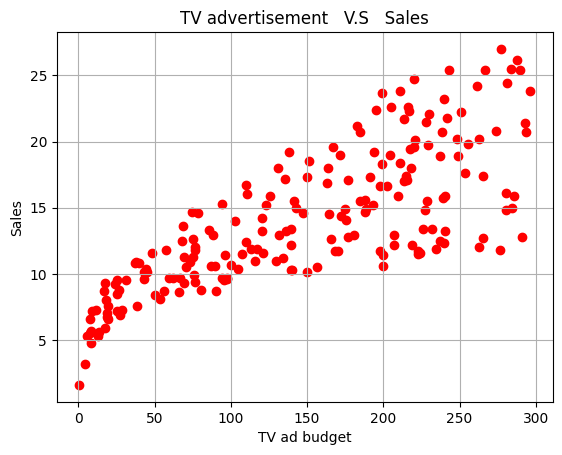

Slope:0.04753664043301975

Intercept:7.032593549127695
TV budget100  |  Sales prediction:11.79

TV budget200  |  Sales prediction:16.54



In [13]:
x_train=df[["TV"]].to_numpy()
y_train=df["Sales"].to_numpy()
print(f"First five imputs:\n{x_train[:5]}")
print(f"\nFirst five targets:\n{y_train[:5]}")
print(f"\nShape of x_train:{x_train.shape}")
print(f"\nShape of y_train:{y_train.shape}")

plt.scatter(x_train,y_train,color='red')
plt.xlabel("TV ad budget")
plt.ylabel("Sales")
plt.title("TV advertisement   V.S   Sales")
plt.grid(True)
plt.show()

model=LinearRegression()
model.fit(x_train,y_train)
print(f"Slope:{model.coef_[0]}")
print(f"\nIntercept:{model.intercept_}")
new_x=np.array([[100],[200]])
predict=model.predict(new_x)
for budget,prediction in zip(new_x.flatten(),predict):
  print(f"TV budget{budget}  |  Sales prediction:{prediction:.2f}\n")

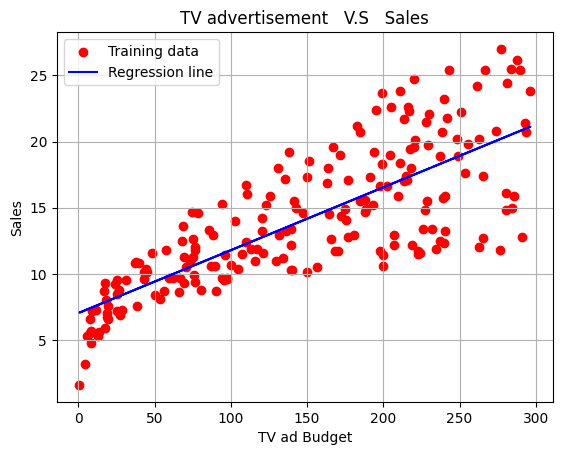

In [16]:
y_pred=model.predict(x_train)
plt.scatter(x_train,y_train,color="red",label="Training data")
plt.plot(x_train,y_pred,color="blue",label="Regression line")
plt.xlabel("TV ad Budget")
plt.ylabel("Sales")
plt.title("TV advertisement   V.S   Sales")
plt.legend()
plt.grid(True)
plt.show()



In [20]:
from sklearn.metrics import mean_squared_error,r2_score
mse=mean_squared_error(y_train,y_pred)
r2=r2_score(y_train,y_pred)
print(f"Mean squared error:{mse:.2f}")
print(f"R2 score:{r2:.4f}")
rmse=np.sqrt(mse)
print(f"Root mean squared error:{rmse:.2f}")
for actual,predicted in zip(y_train[:10],y_pred[:10]):
  print(f"Actual:{actual:.2f}  |  Predicted:{predicted:.2f}")

Mean squared error:10.51
R2 score:0.6119
Root mean squared error:3.24
Actual:22.10  |  Predicted:17.97
Actual:10.40  |  Predicted:9.15
Actual:9.30  |  Predicted:7.85
Actual:18.50  |  Predicted:14.23
Actual:12.90  |  Predicted:15.63
Actual:7.20  |  Predicted:7.45
Actual:11.80  |  Predicted:9.77
Actual:13.20  |  Predicted:12.75
Actual:4.80  |  Predicted:7.44
Actual:10.60  |  Predicted:16.53


## Multiple Linear Regression

In this section, I use Scikit-learn's `LinearRegression` to predict sales using three features: TV, radio, and newspaper advertising budgets.

I evaluate the model using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the coefficient of determination (\(R^2\)).

In [31]:
x=df[["TV", "Radio", "Newspaper"]].to_numpy()
y=df[["Sales"]].to_numpy()
model=LinearRegression()
model.fit(x,y)
y_pred=model.predict(x)

print(f"Intercept: {model.intercept_[0]:.4f}")
for feature, weight in zip(["TV","Radio","Newspaper"],model.coef_[0]):
    print(f"\n{feature:10s}: {weight:.4f}")

mse_2=mean_squared_error(y,y_pred)
r2_2=r2_score(y,y_pred)
print(f"\nMean squared error:{mse_2:.2f}")
print(f"R2 score:{r2_2:.4f}")
rmse_2=np.sqrt(mse_2)
print(f"Root mean squared error:{rmse_2:.2f}")

Intercept: 2.9389

TV        : 0.0458

Radio     : 0.1885

Newspaper : -0.0010

Mean squared error:2.78
R2 score:0.8972
Root mean squared error:1.67


In [39]:
comparison=pd.DataFrame({"Model": ["TV Only","TV+Radio+Newspaper"],"MSE": [mse,mse_2],"RMSE": [rmse,rmse_2],"R²": [r2,r2_2]})
comparison.round(4)

,Model,MSE,RMSE,R²
0,TV Only,10.5127,3.2423,0.6119
1,TV+Radio+Newspaper,2.7841,1.6686,0.8972


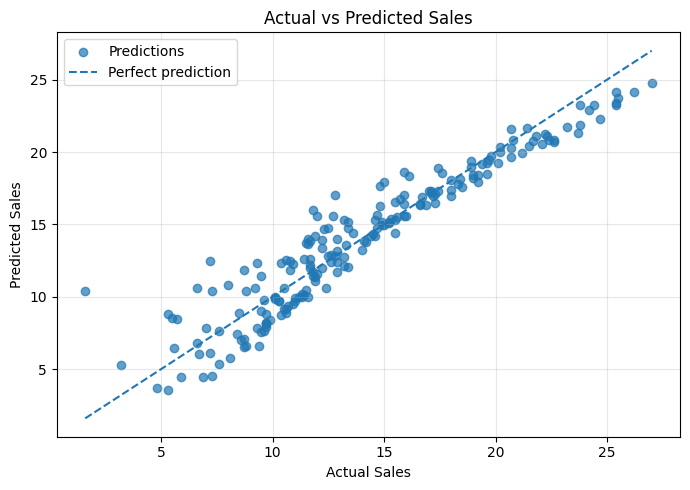

In [40]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7,5))
plt.scatter(y,y_pred,alpha=0.7,label="Predictions")
min_value=min(y.min(),y_pred.min())
max_value=max(y.max(),y_pred.max())
plt.plot([min_value,max_value],[min_value,max_value],linestyle="--",label="Perfect prediction")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()